# Restaurant Tipping Behavior: What Drives Tips?

**Stack:** Python, pandas, seaborn, scikit-learn

> **Project origin.** Originally completed as a weekly assignment in an Introduction to Machine Learning course (KBTU). This version is restructured as a standalone case study and extended with the additional analysis listed below.

**What this version adds**

- tip **percentage** as a size-independent metric (dollar tips mostly just follow the bill)
- significance tests (Welch t-test) instead of eyeballing group means
- regression evaluated on a held-out test set and compared to a naive baseline
- key findings generated from the data, so text and numbers always agree

## Business questions

1. Do customers tip more on weekends?
2. Do gender or smoking status influence tipping?
3. How does the size of the bill affect the tip?

**Data:** the `tips` dataset (244 dining parties): `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, `size`.

In [97]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 1. Data overview

In [100]:
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.describe()

Shape: (244, 7)
Missing values: 0


,total_bill,tip,size
count,244.000,244.000,244.000
mean,19.786,2.998,2.570
std,8.902,1.384,0.951
min,3.070,1.000,1.000
25%,13.348,2.000,2.000
50%,17.795,2.900,2.000
75%,24.127,3.562,3.000
max,50.810,10.000,6.000


## 2. Feature engineering

A larger bill naturally produces a larger tip in dollars, so comparing raw dollar tips between groups can be misleading.
I add **tip percentage** (`tip / total_bill`) as a size-independent measure, and a weekend flag.

In [103]:
df["tip_pct"] = df["tip"] / df["total_bill"] * 100
df["is_weekend"] = df["day"].isin(["Sat", "Sun"])
df[["total_bill", "tip", "tip_pct", "is_weekend"]].head()

,total_bill,tip,tip_pct,is_weekend
0,16.99,1.01,5.945,True
1,10.34,1.66,16.054,True
2,21.01,3.50,16.659,True
3,23.68,3.31,13.978,True
4,24.59,3.61,14.681,True


## 3. Do customers tip more on weekends?

In [106]:
summary = (df.groupby("is_weekend")
             .agg(parties=("tip", "size"),
                  avg_bill=("total_bill", "mean"),
                  avg_tip=("tip", "mean"),
                  avg_tip_pct=("tip_pct", "mean"))
             .rename(index={False: "Weekday (Thu-Fri)", True: "Weekend (Sat-Sun)"}))
summary

,parties,avg_bill,avg_tip,avg_tip_pct
is_weekend,,,,
Weekday (Thu-Fri),81,17.558,2.763,16.330
Weekend (Sat-Sun),163,20.893,3.115,15.956


In [108]:
for col in ["total_bill", "tip", "tip_pct"]:
    a = df.loc[df["is_weekend"], col]
    b = df.loc[~df["is_weekend"], col]
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    print(f"{col:>10}: weekend - weekday = {a.mean() - b.mean():+.3f}   (Welch t-test p = {p:.4f})")

total_bill: weekend - weekday = +3.335   (Welch t-test p = 0.0038)
       tip: weekend - weekday = +0.352   (Welch t-test p = 0.0449)
   tip_pct: weekend - weekday = -0.374   (Welch t-test p = 0.5965)


The test separates *spending more* (the bill) from *tipping more generously* (the percentage).

## 4. Tips by day, time, gender and smoking status

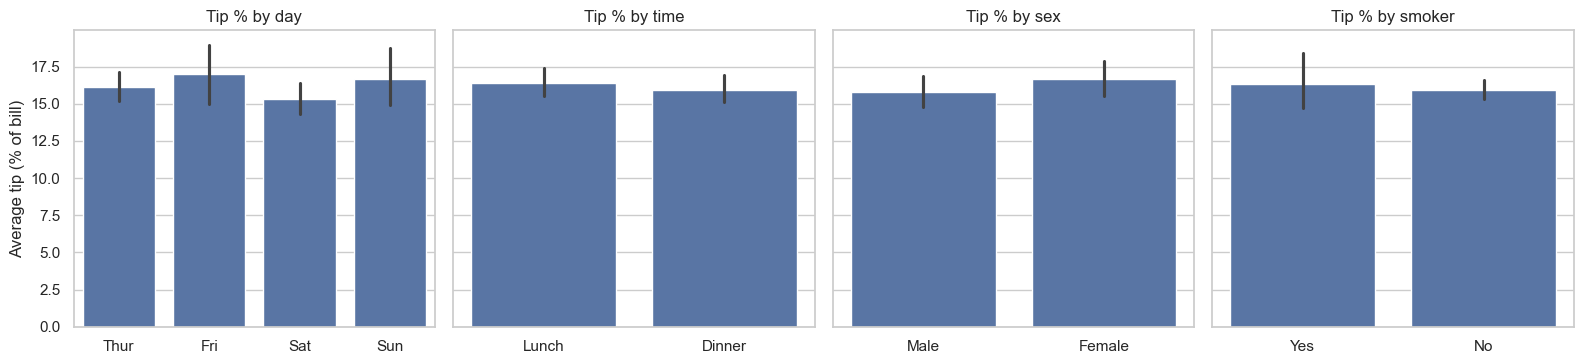

In [112]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col in zip(axes, ["day", "time", "sex", "smoker"]):
    sns.barplot(data=df, x=col, y="tip_pct", ax=ax)
    ax.set_title(f"Tip % by {col}")
    ax.set_xlabel("")
axes[0].set_ylabel("Average tip (% of bill)")
plt.tight_layout()
plt.show()

In [113]:
for col in ["sex", "smoker"]:
    groups = [g["tip_pct"] for _, g in df.groupby(col, observed=True)]
    p = stats.ttest_ind(*groups, equal_var=False).pvalue
    means = df.groupby(col, observed=True)["tip_pct"].mean().round(2).to_dict()
    print(f"{col}: mean tip % = {means}, Welch p = {p:.3f}")

sex: mean tip % = {'Male': 15.77, 'Female': 16.65}, Welch p = 0.254
smoker: mean tip % = {'Yes': 16.32, 'No': 15.93}, Welch p = 0.682


## 5. How does the bill size affect the tip?

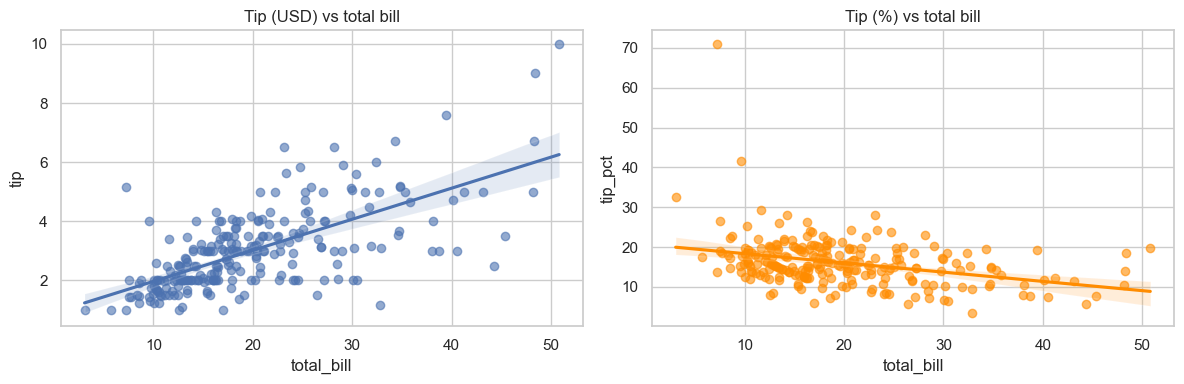

Correlation, bill vs tip (USD): 0.68
Correlation, bill vs tip (%):   -0.34


In [115]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=df, x="total_bill", y="tip", ax=axes[0], scatter_kws={"alpha": 0.6})
axes[0].set_title("Tip (USD) vs total bill")
sns.regplot(data=df, x="total_bill", y="tip_pct", ax=axes[1], scatter_kws={"alpha": 0.6}, color="darkorange")
axes[1].set_title("Tip (%) vs total bill")
plt.tight_layout()
plt.show()

r_dollar = df["total_bill"].corr(df["tip"])
r_pct = df["total_bill"].corr(df["tip_pct"])
print(f"Correlation, bill vs tip (USD): {r_dollar:.2f}")
print(f"Correlation, bill vs tip (%):   {r_pct:.2f}")

## 6. Predicting the tip (linear regression)

The model is trained on 80% of the data and evaluated on the held-out 20%. A naive baseline that always predicts
the average tip shows how much the model actually adds.

In [117]:
X = df[["total_bill"]]
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "R2": [r2_score(y_test, pred), r2_score(y_test, baseline)],
    "RMSE (USD)": [np.sqrt(mean_squared_error(y_test, pred)), np.sqrt(mean_squared_error(y_test, baseline))],
    "MAE (USD)": [mean_absolute_error(y_test, pred), mean_absolute_error(y_test, baseline)],
}, index=["Linear regression", "Baseline (mean tip)"])
display(results)

print(f"Tip = {model.intercept_:.2f} + {model.coef_[0]:.3f} x bill")
new_bill = pd.DataFrame({"total_bill": [30]})
print(f"Predicted tip for a 30 USD bill: {model.predict(new_bill)[0]:.2f} USD")

,R2,RMSE (USD),MAE (USD)
Linear regression,0.545,0.754,0.621
Baseline (mean tip),-0.159,1.204,1.047


Tip = 0.93 + 0.107 x bill
Predicted tip for a 30 USD bill: 4.13 USD


## 7. Key findings

In [119]:
wk, wd = df[df["is_weekend"]], df[~df["is_weekend"]]
p_pct = stats.ttest_ind(wk["tip_pct"], wd["tip_pct"], equal_var=False).pvalue
p_sex = stats.ttest_ind(*[g["tip_pct"] for _, g in df.groupby("sex", observed=True)], equal_var=False).pvalue
p_smk = stats.ttest_ind(*[g["tip_pct"] for _, g in df.groupby("smoker", observed=True)], equal_var=False).pvalue

if p_pct < 0.05:
    weekend_note = (f"The weekend difference in tip percentage ({wk['tip_pct'].mean():.1f}% vs "
                    f"{wd['tip_pct'].mean():.1f}%) is statistically significant (p = {p_pct:.3f}).")
else:
    weekend_note = (f"Tip percentage is about the same ({wk['tip_pct'].mean():.1f}% vs {wd['tip_pct'].mean():.1f}%, "
                    f"p = {p_pct:.2f}), so higher dollar tips on weekends come mainly from larger bills, "
                    "not from more generous tipping.")

if p_sex < 0.05 or p_smk < 0.05:
    group_note = (f"Tip percentage differs by gender (p = {p_sex:.3f}) and/or smoking status "
                  f"(p = {p_smk:.3f}); see the charts in section 4 for the direction.")
else:
    group_note = (f"Neither gender (p = {p_sex:.2f}) nor smoking status (p = {p_smk:.2f}) shows a "
                  "statistically significant effect on tip percentage.")

r2 = results.loc["Linear regression", "R2"]
rmse = results.loc["Linear regression", "RMSE (USD)"]

findings = [
    f"- **Typical tip:** about {df['tip_pct'].median():.0f}% of the bill (median).",
    f"- **Weekends:** average bill {wk['total_bill'].mean():.2f} vs {wd['total_bill'].mean():.2f} USD on weekdays; "
    f"average tip {wk['tip'].mean():.2f} vs {wd['tip'].mean():.2f} USD. {weekend_note}",
    f"- **Gender and smoking:** {group_note}",
    f"- **Bill size:** the bill is the main driver of the dollar tip (r = {r_dollar:.2f}). A linear model explains "
    f"R2 = {r2:.2f} of the variance on unseen data, with a typical error of about {rmse:.2f} USD.",
]
display(Markdown("\n".join(findings)))

- **Typical tip:** about 15% of the bill (median).
- **Weekends:** average bill 20.89 vs 17.56 USD on weekdays; average tip 3.12 vs 2.76 USD. Tip percentage is about the same (16.0% vs 16.3%, p = 0.60), so higher dollar tips on weekends come mainly from larger bills, not from more generous tipping.
- **Gender and smoking:** Neither gender (p = 0.25) nor smoking status (p = 0.68) shows a statistically significant effect on tip percentage.
- **Bill size:** the bill is the main driver of the dollar tip (r = 0.68). A linear model explains R2 = 0.54 of the variance on unseen data, with a typical error of about 0.75 USD.

## 8. Takeaways and limitations

**Takeaways**

- Compare groups by tip *percentage*, not dollars: dollar tips mostly track the size of the bill.
- Test group differences before acting on them. Gaps that look visible in a bar chart can be within noise for a sample this small.

**Limitations**

- Only 244 parties from a single restaurant, so the results may not generalize.
- Observational data: there is no information about service quality, party composition or payment method.
- Only Thursday to Sunday are recorded; Monday to Wednesday are missing.
- A single predictor (bill size) is used, so the regression is intentionally simple.